In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

In [9]:
train = pd.read_csv('train_fe.csv')
test = pd.read_csv('test_fe.csv')

In [13]:
X = train.drop(columns=['id', 'PitNextLap'])
y = train['PitNextLap']
X_test = test.drop(columns=['id'])

cat_cols = ['Driver', 'Compound', 'Race']
for col in cat_cols:
    X[col] = X[col].astype('category')
    X_test[col] = X_test[col].astype('category')

oof_preds = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
    
    model = lgb.LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        scale_pos_weight=10,
        random_state=42,
        n_jobs=-1
    )
    
    # early stopping and logging evaluation metrics during training
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, verbose=False),
            lgb.log_evaluation(period=0)
        ]
    )
    
    val_probs = model.predict_proba(X_va)[:, 1]
    oof_preds[val_idx] = val_probs
    
    test_preds += model.predict_proba(X_test)[:, 1] / skf.n_splits
    
    fold_auc = roc_auc_score(y_va, val_probs)
    print(f"Fold {fold+1} ROC AUC: {fold_auc:.5f}")

total_auc = roc_auc_score(y, oof_preds)
print(f"\nCałkowity OOF ROC AUC: {total_auc:.5f}")


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Number of positive: 69904, number of negative: 281408
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003962 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2571
[LightGBM] [Info] Number of data points in the train set: 351312, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.198980 -> initscore=-1.392683
[LightGBM] [Info] Start training from score -1.392683
Fold 1 ROC AUC: 0.91794
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may 

In [15]:
submission = pd.read_csv('sample_submission.csv')
submission['PitNextLap'] = test_preds
submission.to_csv('baseline_submission.csv', index=False)

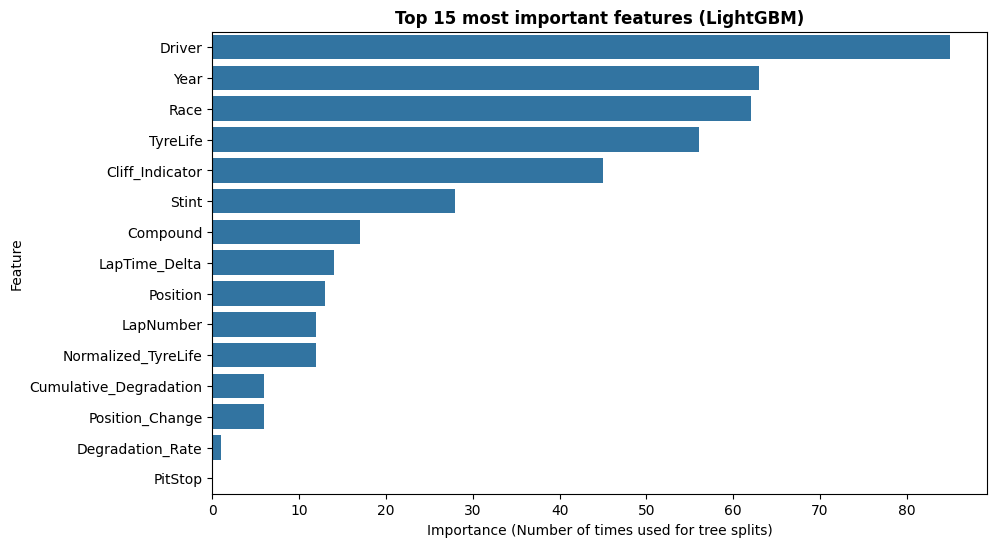

In [18]:
feature_importances = model.feature_importances_

fi_df = pd.DataFrame({
    'Feature': X.columns, 
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=fi_df.head(15), x='Importance', y='Feature')
plt.title('Top 15 most important features (LightGBM)', weight='bold')
plt.xlabel('Importance (Number of times used for tree splits)')
plt.ylabel('Feature')
plt.show()

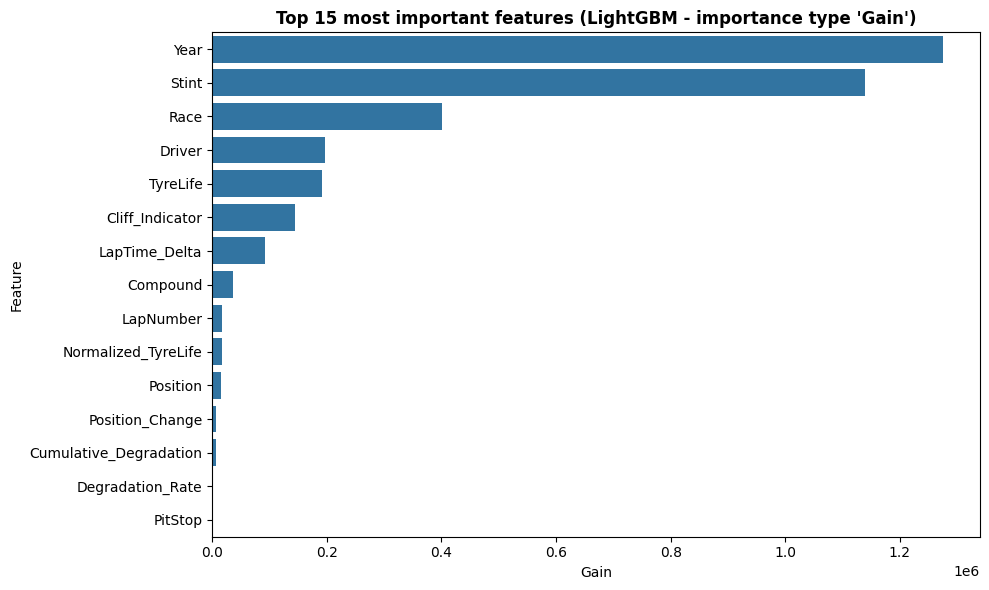

In [19]:
gain_importances = model.booster_.feature_importance(importance_type='gain')

fi_gain_df = pd.DataFrame({
    'Feature': X.columns, 
    'Gain_Importance': gain_importances
}).sort_values(by='Gain_Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=fi_gain_df.head(15), x='Gain_Importance', y='Feature')
plt.title("Top 15 most important features (LightGBM - importance type 'Gain')", weight='bold')
plt.xlabel("Gain")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()